# EOD electric-field solver — *Gnathonemus petersii*, two-layer bodies, recorded waveform

Cleaned-up version of `eod_two_layer_pipeline.ipynb`: same physics, dead code and duplicated
solve logic removed, a couple of latent bugs fixed (see notes inline), one shared
`solve_source_fish` function instead of the same ~15 lines copy-pasted into every plotting cell.

**Setup.** Each fish is a two-layer body (conductive interior + resistive/capacitive skin,
literature values) sitting in water. One fish emits its *recorded* EOD waveform `I(t)`; the
other fish are passive boundaries that distort the field around it.

**Governing equation** (frequency domain, one angular frequency ω at a time):
$$\nabla\cdot(\gamma\,\nabla\hat\varphi) = -\hat s, \qquad \gamma = \sigma + i\omega\varepsilon$$
Solved once per EOD frequency that carries real power, then inverse-FFT'd to `φ(x, y, t)`.
The **E-field is not solved for directly** — it's recovered as `E = -∇φ` via a centered finite
difference (`np.gradient`) on the solved potential grid, same as in `efield_solver.py`.

In [1]:
import re
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.linalg import splu
from scipy.ndimage import zoom
from scipy.interpolate import UnivariateSpline
import matplotlib.pyplot as plt

## 0. Load fish masks

`..._masks_first_1000_frames.npy` → `(n_fish, n_saved_frames, P, P)` boolean. We pick one saved
frame → `(n_fish, P, P)`. `N` is the tank's solve-grid resolution; `n_poles` is how many point
currents approximate one fish's body (a 1-D "multipole" chain along its midline).

In [2]:
mgz_file = 'data/video2024-02-20T21_16_26__223e__59997__masks_packed.mgz'
frame_idx = 2                                      # one of the 3 saved example frames (0, 600, 800)
fish_mask = np.load(f'{mgz_file}_masks_first_1000_frames.npy')[:, frame_idx]   # (n_fish, P, P) bool
n_fish = fish_mask.shape[0]
print(f"fish_mask: {fish_mask.shape} {fish_mask.dtype}, {n_fish} fish")

N = 200         # tank grid resolution (N x N)
n_poles = 100   # current sources placed along each fish's body (n_poles+1 points, tail->head)
h = 1.0 / (N - 1)

fish_mask: (4, 912, 912) bool, 4 fish


## 1. Geometry: grid bookkeeping, curved midline, multipole source placement

`fish_midline_from_mask` fits a smooth curve through the body (PCA axis + spline on the
perpendicular offset) so the current sources below follow the fish's actual bend, not just a
straight line. `multipole_sources` drops a sink at the tail and evenly spaced sources along the
body, arc-length normalized, with total current scaling with body length.

In [3]:
def idx(i, j, N):
    """Flatten a 2D grid coordinate to its 1D index (row-major), for the length-N*N vectors
       the PDE solver works on (build_A_shell, solve_potential).
       i, j: row/col (int), 0 <= i,j < N.  N: int, grid resolution (tank is N x N).
       Returns: int in [0, N*N) -- the flat index i*N + j."""
    return i * N + j

def to_grid(v, N):
    """Inverse of idx: reshape a flat length-N*N vector back into an (N,N) grid for plotting
       or further array ops (e.g. np.gradient for the E-field).
       v: array-like, length N*N (e.g. the potential vector returned by solve_potential).
       N: int, grid resolution.
       Returns: np.ndarray, shape (N,N)."""
    return np.asarray(v).reshape(N, N)

def mask_to_grid(m, N):
    """(P,P) bool -> (N,N) bool on the tank grid (nearest-neighbour, stays binary)."""
    P = m.shape[0]
    if P == N: return m.astype(bool)
    return zoom(m.astype(float), N / P, order=0)[:N, :N] > 0.5

def fish_midline_from_mask(mask, n_ctrl=200, smooth=None):
    """(P,P) bool -> smooth curved midline (n_ctrl,2) in [0,1], oriented tail->head."""
    xs, ys = np.nonzero(mask)
    pts = np.column_stack([xs, ys]).astype(float); c = pts.mean(0)
    v = np.linalg.svd(pts - c, full_matrices=False)[2][0]
    perp = np.array([-v[1], v[0]])
    t = (pts - c) @ v
    w = (pts - c) @ perp

    # average perpendicular offset per unique t (spline needs strictly increasing x)
    order = np.argsort(t); t_s, w_s = t[order], w[order]
    tu, inv, cnt = np.unique(np.round(t_s, 6), return_inverse=True, return_counts=True)
    wu = np.bincount(inv, weights=w_s) / cnt
    L = t_s.max() - t_s.min()
    if smooth is None:
        smooth = len(tu) * (0.05 * L) ** 2             # gentle default
    spl = UnivariateSpline(tu, wu, k=3, s=smooth, w=np.sqrt(cnt))
    ts = np.linspace(t_s.min(), t_s.max(), n_ctrl)
    curve = c + np.outer(ts, v) + np.outer(spl(ts), perp)

    # orient tail->head: the head end is bulkier (more pixels) -> that half goes last
    t_mid = 0.5 * (t.min() + t.max())
    if np.count_nonzero(t < t_mid) > np.count_nonzero(t >= t_mid):
        curve = curve[::-1]

    nx, ny = mask.shape
    return curve / np.array([nx - 1, ny - 1])

def multipole_sources(midline, n, I0=1.0):
    """n+1 point currents spaced evenly by ARC LENGTH along the midline: tail = sink (-1),
       body = uniform sources (+1/n). Total current scales with body length."""
    midline = np.asarray(midline, float)
    seg = np.linalg.norm(np.diff(midline, axis=0), axis=1)
    s = np.concatenate([[0.0], np.cumsum(seg)]); s /= s[-1]
    targets = np.arange(n + 1) / n
    pos = np.column_stack([np.interp(targets, s, midline[:, 0]),
                            np.interp(targets, s, midline[:, 1])])
    length = np.linalg.norm(np.diff(pos, axis=0), axis=1).sum()
    m = np.full(n + 1, 1.0 / n); m[0] = -1.0
    return pos, m * I0 * length

## 2. Two-layer material model

Normalized conductivities (`sigma_water = 1`), from Migliaro/Caputi/Budelli (2005):

| region | σ (conductivity) | ε (permittivity) | basis |
|---|---|---|---|
| water | 1.0 | 0 | resistive |
| interior | 200 | 0 | body ≈ 200× water (measured), funnels current |
| skin | 0.05 | 2.7e-6 | resistive sheet + capacitance → distorts the EOD waveform |

Capacitance lives only in the **skin**; that's what makes the field shape change across the EOD
rather than just scale with it.

In [4]:
MAT = dict(
    sigma_water=1.0,      eps_water=0.0,
    sigma_interior=200.0, eps_interior=0.0,
    sigma_skin=0.05,      eps_skin=2.7e-6,
)

def gammas(omega, **mat):
    """Complex admittivity gamma = sigma + i*omega*eps, per material."""
    gw = mat['sigma_water']    + 1j*omega*mat['eps_water']
    gs = mat['sigma_skin']     + 1j*omega*mat['eps_skin']
    gi = mat['sigma_interior'] + 1j*omega*mat['eps_interior']
    return gw, gs, gi

## 3. Body geometry on the grid + matrix assembly

`occupancy_field` is a smoothly-interpolated occupancy level-set (not a binary mask), so the
water|fish boundary can sit *between* grid points. `build_A_shell` places the skin as a
sub-cell shell offset inward from that boundary by `delta_h` cells, and composes
water→skin→interior in series per edge — so the resistive+capacitive skin is resolved without
needing a finer grid. `A` is complex-symmetric, so it's solved with a direct LU, not CG.

In [5]:
def occupancy_field(masks, N, skip=None):
    """(n_fish,P,P) bool -> smooth NxN occupancy in [0,1]; occ > 0.5 = inside a fish.
       Linear interpolation keeps fractional values at the boundary. `skip` excludes one fish
       (the emitter) so it's transparent to water."""
    occ = np.zeros((N, N))
    for f, m in enumerate(masks):
        if f == skip or not np.any(m): continue
        P = m.shape[0]
        occ = np.maximum(occ, zoom(m.astype(float), N / P, order=1)[:N, :N])
    return occ

def theta_outer(occ, level=0.5):
    """Fractional position of the water|fish boundary on each grid edge (NaN = uncut)."""
    def cross(a, b):
        cut = (a - level) * (b - level) < 0
        d = a - b
        th = np.divide(a - level, d, out=np.full_like(a, np.nan), where=np.abs(d) > 1e-12)
        return np.where(cut, np.clip(th, 1e-6, 1 - 1e-6), np.nan)
    return cross(occ[:-1, :], occ[1:, :]), cross(occ[:, :-1], occ[:, 1:])

def _edge_weight(gC, gM, occC, occM, thc, delta_h, g_water, g_skin, g_interior):
    """Effective admittivity across one grid edge, composing water|skin|interior in SERIES.
       thc = outer (water|fish) crossing from node C; delta_h = skin thickness in cell units."""
    if np.isnan(thc):
        return gC if gC == gM else 2*gC*gM/(gC+gM)         # uncut edge: harmonic mean
    inward = 1.0 if occM > occC else -1.0
    th_in = thc + inward * delta_h                          # inner (skin|interior) crossing
    cuts = sorted(t for t in (thc, th_in) if 1e-6 < t < 1 - 1e-6)
    pts = [0.0] + cuts + [1.0]
    Z = 0.0
    for a, b in zip(pts[:-1], pts[1:]):
        xm = 0.5 * (a + b)
        d_out, d_in = (xm - thc) * inward, (xm - th_in) * inward
        g = g_water if d_out < 0 else (g_interior if d_in > 0 else g_skin)
        Z += (b - a) / g
    return 1.0 / Z

def build_A_shell(occ, N, delta_h, g_water, g_skin, g_interior):
    """Complex system matrix for div(gamma grad phi) = -s, with the skin resolved as a
       sub-cell shell at the actual occupancy boundary (not snapped to the grid)."""
    tx, ty = theta_outer(occ)
    gnode = np.where(occ > 0.5, g_interior, g_water)
    r, c, v = [], [], []
    def edge(k, kk, gC, gM, oC, oM, thc):
        w = _edge_weight(gC, gM, oC, oM, thc, delta_h, g_water, g_skin, g_interior)
        r.append(k); c.append(kk); v.append(w); return w
    for i in range(N):
        for j in range(N):
            k = idx(i, j, N); ws = 0j
            if i > 0:   ws += edge(k, idx(i-1,j,N), gnode[i,j], gnode[i-1,j], occ[i,j], occ[i-1,j], 1-tx[i-1,j])
            if i < N-1: ws += edge(k, idx(i+1,j,N), gnode[i,j], gnode[i+1,j], occ[i,j], occ[i+1,j],   tx[i,  j])
            if j > 0:   ws += edge(k, idx(i,j-1,N), gnode[i,j], gnode[i,j-1], occ[i,j], occ[i,j-1], 1-ty[i,j-1])
            if j < N-1: ws += edge(k, idx(i,j+1,N), gnode[i,j], gnode[i,j+1], occ[i,j], occ[i,j+1],   ty[i,  j])
            r.append(k); c.append(k); v.append(-ws)
    return sp.coo_matrix((v, (r, c)), shape=(N*N, N*N), dtype=complex).tocsr()

def solve_potential(A, b, pin=0):
    """Solve A phi = b (singular complex Neumann system); pin one node to fix the gauge."""
    M = (-A).tolil(); rhs = -np.asarray(b).ravel().astype(complex)
    M[pin, :] = 0; M[pin, pin] = 1; rhs[pin] = 0
    phi = splu(M.tocsc()).solve(rhs)
    return phi - phi.mean()

## 4. Source deposition on the grid

Each point current is spread onto its 4 surrounding grid nodes by bilinear weights.

In [6]:
def place_current_on_grid(b, x, y, I, h, N):
    fi, fj = x/h, y/h; i, j = int(fi), int(fj); a, c = fi-i, fj-j
    for di, wx in ((0, 1-a), (1, a)):
        for dj, wy in ((0, 1-c), (1, c)):
            ii, jj = i+di, j+dj
            if 0 <= ii < N and 0 <= jj < N: b[ii, jj] += I*wx*wy

def build_multipole_b(pos, cur, h, N):
    b = np.zeros((N, N))
    for (x, y), Ii in zip(pos, cur): place_current_on_grid(b, x, y, Ii, h, N)
    return b - b.mean()            # enforce net current = 0 (required for the Neumann solve)

## 5. Recorded EOD → I(t), its power spectrum, and the electrode layout

Only the rfft bins that carry `power_keep` of the signal's power are solved for (the rest are
noise and would just waste LU factorizations).

In [7]:
def load_eod_row(df, row=0, fs=20000.0):
    """One EOD row of the CSV -> E (n_elec, n_time), index of the most active electrode, dt."""
    pat = re.compile(r"electrode_(\d+)_time_(\d+)")
    cells = [(int(m.group(1)), int(m.group(2)), col) for col in df.columns for m in [pat.match(col)] if m]
    ne, nt = max(e for e, _, _ in cells), max(t for _, t, _ in cells)
    E = np.full((ne, nt), np.nan)
    for e, t, col in cells: E[e-1, t-1] = df.iloc[row][col]
    best = int(np.argmax(E.std(axis=1)))                   # most active electrode
    return E, best, 1.0/fs

def eod_frequencies(I_rec, dt, power_keep=0.999, detrend=True):
    """Which rfft bins carry `power_keep` of the signal's power (amplitude is irrelevant)."""
    x = np.asarray(I_rec, float); x = x - x.mean() if detrend else x
    n = len(x); Ihat = np.fft.rfft(x); f = np.fft.rfftfreq(n, dt); Pw = np.abs(Ihat)**2
    order = np.argsort(Pw)[::-1]; frac = np.cumsum(Pw[order]) / Pw.sum()
    nk = int(np.searchsorted(frac, power_keep) + 1)
    keep = np.sort(order[:nk]); keep = keep[f[keep] > 0]    # drop DC
    return keep, 2*np.pi*f, Ihat, n, f, Pw

def load_electrode_pairs(csv, N_px=912):
    """Electrode (x,y) pixel coords -> [0,1] tank-frame coords, grouped into +/- pairs."""
    df = pd.read_csv(csv)
    pairs = []
    for _, r in df.iterrows():
        if str(r['pol1']).strip() == '+':
            (x1, y1), (x2, y2) = (r['x1'], r['y1']), (r['x2'], r['y2'])
        else:
            (x1, y1), (x2, y2) = (r['x2'], r['y2']), (r['x1'], r['y1'])
        to_tank = lambda x, y: np.array([y/(N_px-1), x/(N_px-1)])   # matches the mask/tank axes
        pairs.append((int(r['pair']), to_tank(x1, y1), to_tank(x2, y2)))
    return pairs

electrode #1 | 25 samples @ 20 kHz | solving 9 freqs: [0.8 1.6 2.4 3.2 4.  4.8 5.6 6.4 7.2] kHz


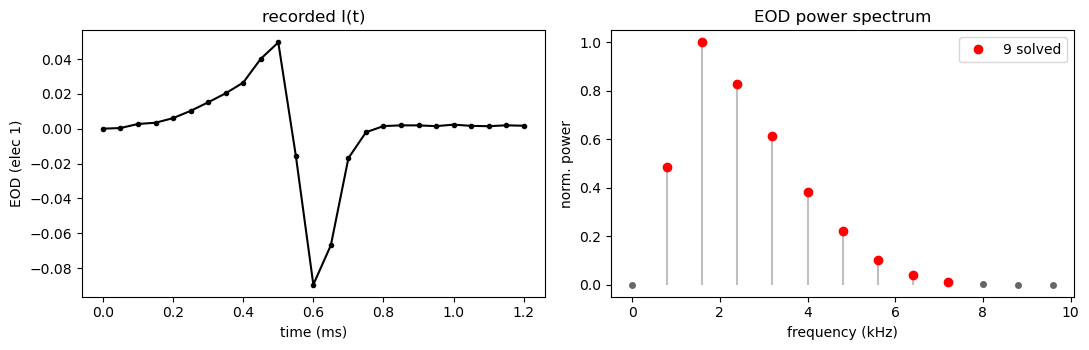

In [8]:
eod_csv = 'data/Data_4fish_2024-02-20T21_16_26.csv'
df_eod = pd.read_csv(eod_csv)

chosen_eod_frame = 25
E, best, dt = load_eod_row(df_eod, row=chosen_eod_frame, fs=20000.0)
I_rec = E[best]
It = I_rec - I_rec.mean()
keep, om, Ihat, n_t, freqs, Pw = eod_frequencies(I_rec, dt)
print(f"electrode #{best+1} | {n_t} samples @ {1/dt/1e3:.0f} kHz | "
      f"solving {len(keep)} freqs: {np.round(freqs[keep]/1e3, 2)} kHz")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(np.arange(n_t)*dt*1e3, It, 'ko-', ms=3)
ax[0].set_xlabel("time (ms)"); ax[0].set_ylabel(f"EOD (elec {best+1})"); ax[0].set_title("recorded I(t)")
ax[1].vlines(freqs/1e3, 0, Pw/Pw.max(), color='0.75')
ax[1].plot(freqs/1e3, Pw/Pw.max(), 'o', color='0.4', ms=4)
ax[1].plot(freqs[keep]/1e3, (Pw/Pw.max())[keep], 'ro', label=f"{len(keep)} solved")
ax[1].set_xlabel("frequency (kHz)"); ax[1].set_ylabel("norm. power"); ax[1].set_title("EOD power spectrum")
ax[1].legend(); plt.tight_layout(); plt.show()

electrode_locations_file = 'data/electrodes_signed_px_coord_2024-02-13.csv'
pairs = load_electrode_pairs(electrode_locations_file)

## 6. Core solver: one fish emits, the others are two-layer boundaries

One function, called for every (source fish × time-domain field) below — the original notebook
rebuilt this same ~15-line block inline in five separate plotting cells (and in one of them read
a stale `occ_with` left over from a previous cell instead of that cell's own `occ`; harmless only
because the two conductivities happened to cancel out algebraically there). Solving per-frequency
is always needed here since the skin is capacitive (`eps_skin != 0`), so there's no resistive
shortcut to fall back on.

In [9]:
def solve_source_fish(fish_mask, N, source_fish, Ihat, om, keep, n_t, delta_h=0.5,
                       n_poles=100, **mat):
    """Full-grid phi(x,y,t) for `source_fish` emitting (its own body is transparent to
       water). Solved once per kept EOD frequency, then inverse-FFT'd. Returns both:
       - phi_with:  the other fish present as two-layer (skin+interior) shell bodies
       - phi_water: identical source/geometry but uniform water everywhere (gw=gs=gi)
       so phi_with - phi_water isolates the perturbation caused by the OTHER fish."""
    h = 1.0 / (N - 1)
    midline = fish_midline_from_mask(fish_mask[source_fish])
    pos, cur = multipole_sources(midline, n=n_poles, I0=1.0)
    b_unit = build_multipole_b(pos, cur, h, N)
    occ = occupancy_field(fish_mask, N, skip=source_fish)

    psi_with  = np.zeros((len(om), N*N), complex)
    psi_water = np.zeros((len(om), N*N), complex)
    for k in keep:
        gw, gs, gi = gammas(om[k], **mat)
        psi_with[k]  = solve_potential(build_A_shell(occ, N, delta_h, gw, gs, gi), b_unit)
        psi_water[k] = solve_potential(build_A_shell(occ, N, delta_h, gw, gw, gw), b_unit)

    phi_with  = np.fft.irfft(Ihat[:, None] * psi_with,  n=n_t, axis=0)
    phi_water = np.fft.irfft(Ihat[:, None] * psi_water, n=n_t, axis=0)
    return dict(phi_with=phi_with, phi_water=phi_water, pos=pos, cur=cur)

## 7. Sanity check

The emitting fish must be excluded from its own body's geometry (it's a source, not an
obstacle) — otherwise the solve would double-count its skin as a boundary around its own
current sources.

In [10]:
source_fish = 0
occ_check = occupancy_field(fish_mask, N, skip=source_fish)
on_src_body = occ_check[mask_to_grid(fish_mask[source_fish], N)]
assert on_src_body.max() < 0.5, "source fish leaking into its own occupancy field"
print("OK: source fish is excluded from its own body geometry")

OK: source fish is excluded from its own body geometry


## 8. Example field frames, using the actual fish bodies

Source fish 0 (dashed yellow outline) emits; fish 1-3 (solid lime outlines) are real body masks
from the tracked video frame. Top row: potential `φ` with streamlines of `E = -∇φ` (finite
difference via `np.gradient`, not an analytic gradient). Bottom row: the perturbation
`Δφ = φ_with − φ_without` caused by the other fish — since the skin is capacitive, this changes
*shape*, not just amplitude, across the EOD.

In [11]:
source_fish = 0
delta_h = 0.5                        # skin thickness, in grid-cell units
res = solve_source_fish(fish_mask, N, source_fish, Ihat, om, keep, n_t,
                         delta_h=delta_h, n_poles=n_poles, **MAT)
phi_with, phi_water, pos, cur = res['phi_with'], res['phi_water'], res['pos'], res['cur']
dphi = phi_with - phi_water
srcp, snkp = cur > 0, cur < 0

half = n_t // 2
vP = np.percentile(np.abs(phi_with[:half]), 99.5)
vD = np.percentile(np.abs(dphi[:half]), 99.0)
g = np.linspace(0, 1, N)

def outline(ax):
    for f, m in enumerate(fish_mask):
        if not m.any(): continue
        is_src = f == source_fish
        ax.contour(g, g, mask_to_grid(m, N).T.astype(float), levels=[0.5],
                   colors=["#FFD400" if is_src else "lime"],
                   linewidths=1.8 if is_src else 1.0, linestyles="--" if is_src else "-")

frames = [0, n_t // 8, n_t // 4]       # a few example timepoints across the first quarter of the EOD
fig, axes = plt.subplots(2, len(frames), figsize=(4*len(frames), 7.5))
for col, ti in enumerate(frames):
    phi, dp = to_grid(phi_with[ti], N), to_grid(dphi[ti], N)
    dpx, dpy = np.gradient(phi, h); Ex, Ey = -dpx, -dpy     # E = -grad(phi), finite-difference approx

    ax = axes[0, col]
    im = ax.imshow(phi.T, origin="lower", extent=[0,1,0,1], cmap="RdBu_r", vmin=-vP, vmax=vP)
    if np.ptp(phi) > 0: ax.streamplot(g, g, Ex.T, Ey.T, color="k", density=0.7, linewidth=0.4, arrowsize=0.5)
    outline(ax); ax.plot(pos[:,0], pos[:,1], "-", color="0.2", lw=1)
    ax.scatter(*pos[srcp].T, c="#C0392B", s=14, ec="k", lw=0.3)
    ax.scatter(*pos[snkp].T, marker="s", c="#2C6FBB", s=32, ec="k", lw=0.5)
    fig.colorbar(im, ax=ax, fraction=0.046, label=r"$\varphi$")
    ax.set_title(f"t = {ti*dt*1e3:.2f} ms, I(t) = {It[ti]:+.3f}", fontsize=9)

    ax = axes[1, col]
    im = ax.imshow(dp.T, origin="lower", extent=[0,1,0,1], cmap="RdBu_r", vmin=-vD, vmax=vD)
    outline(ax)
    fig.colorbar(im, ax=ax, fraction=0.046, label=r"$\Delta\varphi$")
    ax.set_title("perturbation from other fish", fontsize=9)

for ax in axes.ravel():
    ax.set_xlim(0,1); ax.set_ylim(0,1); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"source fish {source_fish} (dashed yellow) — φ + E-field (top), "
             r"$\Delta\varphi$ = with $-$ without other fish (bottom)", fontsize=11)
plt.tight_layout(); plt.show()

## 9. Compare simulated vs. recorded electrode-pair voltages

For each fish in turn as the assumed emitter, sample the solved field at the real electrode-pair
locations and compare to the recorded trace — this is the check for whether the model (and which
candidate source fish) reproduces the real measurement.

In [ ]:
def sample_phi_t(phi_t, p, h, N):
    """Bilinear sample of a (n_t, N*N) field at tank-frame point p=(x,y)."""
    fi, fj = p[0]/h, p[1]/h; i, j = int(fi), int(fj); a, c = fi-i, fj-j
    w = lambda ii, jj: phi_t[:, idx(min(max(ii,0),N-1), min(max(jj,0),N-1), N)]
    return (1-a)*(1-c)*w(i,j) + a*(1-c)*w(i+1,j) + (1-a)*c*w(i,j+1) + a*c*w(i+1,j+1)

def rec_trace(pid, row):
    et = [f'electrode_{pid}_time_{i}' for i in range(1, n_t + 1)]
    vr = np.array(df_eod.loc[row, et], dtype=float)
    return vr - vr.mean()

V_rec = {pid: rec_trace(pid, chosen_eod_frame) for pid, _, _ in pairs}
rec_peak = max(np.abs(v).max() for v in V_rec.values())
V_rec = {pid: v / rec_peak for pid, v in V_rec.items()}          # recorded peak -> 1

V_sim = {}                                                       # V_sim[source_fish][pid]
for sf in range(n_fish):
    res = solve_source_fish(fish_mask, N, sf, Ihat, om, keep, n_t,
                             delta_h=delta_h, n_poles=n_poles, **MAT)
    V_pairs = {pid: sample_phi_t(res['phi_with'], pp, h, N) - sample_phi_t(res['phi_with'], pm, h, N)
               for pid, pp, pm in pairs}
    sim_peak = max(np.abs(v).max() for v in V_pairs.values())
    V_sim[sf] = {pid: v / sim_peak for pid, v in V_pairs.items()}  # each fish's own peak -> 1
    print(f"solved fish {sf} as source (peak |V| = {sim_peak:.3g})")

In [ ]:
from matplotlib.gridspec import GridSpec

t_ms = np.arange(n_t) * dt * 1e3
colors_fish = plt.cm.tab10.colors
npair = len(pairs); ncol = 2; nrow = int(np.ceil(npair / ncol))
fig = plt.figure(figsize=(11, 3.6 * nrow))
gs = GridSpec(nrow, ncol, figure=fig, hspace=0.5, wspace=0.25)
for k, (pid, _, _) in enumerate(pairs):
    ax = fig.add_subplot(gs[k])
    for sf in range(n_fish):
        ax.plot(t_ms, V_sim[sf][pid], color=colors_fish[sf], lw=1.3, label=f"fish {sf} as source")
    ax.plot(t_ms, V_rec[pid], color='black', lw=1.8, label="recorded")
    ax.axhline(0, color='0.85', lw=0.5); ax.set_ylim(-1.1, 1.1)
    ax.set_title(f"electrode pair {pid}", fontsize=9)
    if k == 0: ax.legend(fontsize=6, ncol=2)
fig.suptitle("peak-normalized electrode-pair voltage: simulated (colored) vs recorded (black)", fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

## 10. EOD-cycle video: real recorded EODs, attributed to whichever fish was closest

Sections 8-9 reconstruct the *full* time-resolved waveform for one source fish at a time
(one LU solve per kept frequency, then an inverse FFT) — accurate, but too slow to repeat for
every frame of a long animation. Here we trade that for a single **quasi-static** solve per
EOD event: at the instant a fish's EOD is at its *peak* current, `dI/dt ≈ 0`, so the capacitive
skin term contributes negligibly and `gamma ≈ sigma` (purely resistive, one real LU solve,
no frequency loop). That's the "instant field" — a snapshot, not the transient shape.

Rather than a synthetic choice of which fish fires, this uses the `df_eod` rows actually
recorded (`Frame` column) within each displayed frame's window — those are real detected EODs,
not invented ones. A displayed frame can have zero, one, or several real EOD rows in its window
(multiple fish *can* genuinely discharge within the same ~20 ms video frame); if there's more
than one, one is picked at random — if there's exactly one, that's the one shown. Whichever row
is picked still needs a fish attached to it: the CSV doesn't label *who* fired, so
`attribute_eod_fish` guesses by proximity — the electrode pair with the largest recorded
amplitude should be nearest the true emitter, so whichever fish's body is closest to that pair
is the one credited. The real capture is 50 fps; with ~1000 frames available and
`duration_s=30`, playback is stretched to ~1.5x slower than real time.

In [ ]:
import matplotlib.animation as animation

def solve_instant_field(fish_mask_frame, N, source_fish, I_peak, delta_h=0.5, n_poles=100, **mat):
    """Quasi-static potential for `source_fish` discharging at peak current I_peak, with the
       other fish (this frame's real body masks) as two-layer boundaries. One resistive-only
       LU solve (omega=0) instead of the per-frequency reconstruction used above."""
    h = 1.0 / (N - 1)
    midline = fish_midline_from_mask(fish_mask_frame[source_fish])
    pos, cur = multipole_sources(midline, n=n_poles, I0=I_peak)
    b = build_multipole_b(pos, cur, h, N)
    occ = occupancy_field(fish_mask_frame, N, skip=source_fish)
    gw, gs, gi = gammas(0.0, **mat)                 # omega=0 -> resistive-only (eps term vanishes)
    phi = solve_potential(build_A_shell(occ, N, delta_h, gw, gs, gi), b).real
    return to_grid(phi, N), pos, cur

def attribute_eod_fish(row, pairs, fish_mask_frame):
    """Guess which fish emitted this recorded EOD row: the electrode pair with the largest
       recorded peak amplitude should be nearest the true emitter, so credit whichever fish's
       body (in THIS frame's masks) is closest to that pair's midpoint. Returns (fish_idx or
       None if no fish detected this frame, that pair's peak amplitude)."""
    best_amp, best_mid = -1.0, None
    for pid, pp, pm in pairs:
        v = row[[f'electrode_{pid}_time_{i}' for i in range(1, 26)]].to_numpy(dtype=float)
        amp = np.nanmax(np.abs(v - np.nanmean(v)))
        if amp > best_amp:
            best_amp, best_mid = amp, 0.5 * (pp + pm)
    candidates = [f for f in range(fish_mask_frame.shape[0]) if fish_mask_frame[f].any()]
    if not candidates or best_mid is None:
        return None, best_amp
    def centroid(m):                                 # mean position in the same (row,col) tank frame as `pairs`
        xs, ys = np.nonzero(m)
        return np.array([xs.mean(), ys.mean()]) / (m.shape[0] - 1)
    sf = min(candidates, key=lambda f: np.linalg.norm(centroid(fish_mask_frame[f]) - best_mid))
    return sf, best_amp

In [ ]:
def render_eod_cycle_video(mask_path, df_eod, pairs, N, out_path="eod_cycle.mp4", duration_s=30,
                           frame_stride=10, seed=0, delta_h=0.5, n_poles=100, **mat):
    """Animate real tracked body motion, sampled every `frame_stride` real frames. Each sampled
       frame owns a window of `frame_stride` real frames; any recorded EOD rows (df_eod.Frame,
       1-indexed) falling in that window are real candidates -- one is chosen at random if
       there's more than one, used as-is if there's exactly one, and the frame is left holding
       its previous field if there are none. `attribute_eod_fish` assigns the fish. Output
       always plays back over `duration_s` seconds, regardless of `frame_stride` -- only the
       body-motion resolution changes."""
    rng = np.random.default_rng(seed)
    all_masks = np.load(mask_path, mmap_mode='r')               # (n_fish, n_real_frames, P, P)
    n_real_frames = all_masks.shape[1]
    frame_ids = np.arange(0, n_real_frames, frame_stride)
    fps = max(len(frame_ids) / duration_s, 1.0)
    g = np.linspace(0, 1, N)

    slot_of_row = (df_eod['Frame'] - 1) // frame_stride          # Frame is 1-indexed; masks are 0-indexed
    rows_by_slot = df_eod.groupby(slot_of_row).groups            # slot -> real df_eod row labels in that window

    fig, ax = plt.subplots(figsize=(6, 5.5))
    im = ax.imshow(np.zeros((N, N)), origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r")
    fig.colorbar(im, ax=ax, fraction=0.046, label=r"$\varphi$")
    title = ax.set_title("")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    drawn = []                                                   # per-frame artists to clear
    held = dict(phi=np.zeros((N, N)), pos=None, cur=None, sf=None)
    eod_frames_shown = set()          # a set, not a counter: FuncAnimation.save() can redraw frame 0 twice

    def update(i):
        for art in drawn: art.remove()
        drawn.clear()
        fr = frame_ids[i]
        frame_masks = np.asarray(all_masks[:, fr])               # pulled from disk for this frame only

        row_labels = list(rows_by_slot.get(i, []))                # real EODs in this frame's window
        if row_labels:
            row = df_eod.loc[rng.choice(row_labels)]              # >1 real candidate -> pick one at random
            sf, amp = attribute_eod_fish(row, pairs, frame_masks)
            if sf is not None:
                phi, pos, cur = solve_instant_field(frame_masks, N, sf, amp, delta_h, n_poles, **mat)
                held.update(phi=phi, pos=pos, cur=cur, sf=sf)
                eod_frames_shown.add(i)

        vP = np.percentile(np.abs(held["phi"]), 99.5) or 1.0
        im.set_data(held["phi"].T); im.set_clim(-vP, vP)

        for f, m in enumerate(frame_masks):
            if not m.any(): continue
            is_src = f == held["sf"]
            cs = ax.contour(g, g, mask_to_grid(m, N).T.astype(float), levels=[0.5],
                             colors=["#FFD400" if is_src else "lime"],
                             linewidths=1.8 if is_src else 1.0, linestyles="--" if is_src else "-")
            drawn.append(cs)
        if held["pos"] is not None:
            srcp, snkp = held["cur"] > 0, held["cur"] < 0
            drawn.append(ax.scatter(*held["pos"][srcp].T, c="#C0392B", s=14, ec="k", lw=0.3))
            drawn.append(ax.scatter(*held["pos"][snkp].T, marker="s", c="#2C6FBB", s=32, ec="k", lw=0.5))
        sf_txt = f"fish {held['sf']} fires" if held["sf"] is not None else "no EOD yet"
        title.set_text(f"frame {fr}/{n_real_frames - 1} ({len(row_labels)} real EOD(s) this window) — {sf_txt}")
        return [im]

    anim = animation.FuncAnimation(fig, update, frames=len(frame_ids), interval=1000 / fps, blit=False)
    anim.save(out_path, writer=animation.FFMpegWriter(fps=fps, bitrate=2000), dpi=130)
    plt.close(fig)
    print(f"saved {out_path}: {len(frame_ids)} frames @ {fps:.2f} fps -> {len(frame_ids)/fps:.1f}s, "
          f"{len(eod_frames_shown)}/{len(frame_ids)} frames show a real EOD")
    return out_path

Render it. Each shown EOD uses *that row's own* recorded peak amplitude as its current
scale (not one fixed reference value), so field strength varies realistically event to event.
`frame_stride=10` windows real frames 10 at a time; `seed` makes the random tie-break
(when a window has several real EODs) reproducible.

In [ ]:
mask_path = f'{mgz_file}_masks_first_1000_frames.npy'

render_eod_cycle_video(mask_path, df_eod, pairs, N, out_path="eod_cycle.mp4",
                       duration_s=30, frame_stride=10, seed=0,
                       delta_h=delta_h, n_poles=n_poles, **MAT)

## 11. Per-fish EOD videos, side by side

Section 10 picks (at most) one fish per displayed frame to show. Here each of the 4 fish gets
its *own* video over the identical frame range and sampling: a frame shows that fish's field
only if *it* (per `attribute_eod_fish`) was the real attributed emitter somewhere in that
frame's window — otherwise the panel is left blank (`phi = 0` everywhere, no field, no
multipole markers), rather than falling back to another fish or holding a stale one. Because
all 4 share the same `frame_ids` and the same random draws (same `seed`), they stay in sync
frame-for-frame, so stacking them side by side (plain `ffmpeg hstack`, reusing the already-
rendered mp4s instead of re-solving anything) lines up correctly. Run at both `frame_stride=5`
and `frame_stride=10` to compare a finer vs. coarser sampling of the same real window.

In [ ]:
import subprocess

def render_single_fish_video(mask_source, df_eod, pairs, N, target_fish, out_path, duration_s=30,
                             frame_stride=10, seed=0, delta_h=0.5, n_poles=100, **mat):
    """Like render_eod_cycle_video (section 10), but only ever shows `target_fish`'s own real
       EODs: a frame where `target_fish` wasn't the attributed emitter in its window is left
       blank (phi=0, no markers) instead of showing another fish or holding the last field.
       `mask_source` is either a path to a dense (n_fish, n_frames, P, P) .npy (mmap'd), or a
       {frame_idx: (n_fish,P,P) bool} dict of only the frames actually needed (e.g. from
       `load_frames_from_mgz`) -- useful when the needed range is too large to materialize
       densely."""
    rng = np.random.default_rng(seed)
    if isinstance(mask_source, dict):
        get_frame_masks = mask_source.__getitem__
        n_real_frames = max(mask_source) + 1
    else:
        all_masks = np.load(mask_source, mmap_mode='r')
        get_frame_masks = lambda fr: np.asarray(all_masks[:, fr])
        n_real_frames = all_masks.shape[1]
    frame_ids = np.arange(0, n_real_frames, frame_stride)
    fps = max(len(frame_ids) / duration_s, 1.0)
    g = np.linspace(0, 1, N)

    slot_of_row = (df_eod['Frame'] - 1) // frame_stride
    rows_by_slot = df_eod.groupby(slot_of_row).groups

    fig, ax = plt.subplots(figsize=(5, 5))
    im = ax.imshow(np.zeros((N, N)), origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r", vmin=-1, vmax=1)
    title = ax.set_title("")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    drawn = []
    fired_frames = set()

    def update(i):
        for art in drawn: art.remove()
        drawn.clear()
        fr = frame_ids[i]
        frame_masks = get_frame_masks(fr)

        my_candidates = []                                         # this window's rows attributed to target_fish
        for lbl in rows_by_slot.get(i, []):
            row = df_eod.loc[lbl]
            sf, amp = attribute_eod_fish(row, pairs, frame_masks)
            if sf == target_fish:
                my_candidates.append(amp)

        fired = bool(my_candidates) and frame_masks[target_fish].any()
        if fired:
            amp = my_candidates[int(rng.integers(len(my_candidates)))] if len(my_candidates) > 1 else my_candidates[0]
            phi, pos, cur = solve_instant_field(frame_masks, N, target_fish, amp, delta_h, n_poles, **mat)
            vP = np.percentile(np.abs(phi), 99.5) or 1.0
            im.set_data(phi.T); im.set_clim(-vP, vP)
            fired_frames.add(i)
        else:
            im.set_data(np.zeros((N, N))); im.set_clim(-1, 1)       # blank: no field this frame

        for f, m in enumerate(frame_masks):
            if not m.any(): continue
            is_target = f == target_fish
            cs = ax.contour(g, g, mask_to_grid(m, N).T.astype(float), levels=[0.5],
                             colors=["#FFD400" if is_target else "lime"],
                             linewidths=1.8 if is_target else 1.0,
                             linestyles=("--" if fired else ":") if is_target else "-")
            drawn.append(cs)
        if fired:
            srcp, snkp = cur > 0, cur < 0
            drawn.append(ax.scatter(*pos[srcp].T, c="#C0392B", s=14, ec="k", lw=0.3))
            drawn.append(ax.scatter(*pos[snkp].T, marker="s", c="#2C6FBB", s=32, ec="k", lw=0.5))
        title.set_text(f"fish {target_fish} — frame {fr}/{n_real_frames - 1} — " + ("fires" if fired else "silent"))
        return [im]

    anim = animation.FuncAnimation(fig, update, frames=len(frame_ids), interval=1000 / fps, blit=False)
    anim.save(out_path, writer=animation.FFMpegWriter(fps=fps, bitrate=2000), dpi=130)
    plt.close(fig)
    print(f"saved {out_path}: fish {target_fish}, {len(frame_ids)} frames @ {fps:.2f} fps -> "
          f"{len(frame_ids) / fps:.1f}s, {len(fired_frames)}/{len(frame_ids)} frames fired")
    return out_path

def combine_videos_side_by_side(paths, out_path):
    """Stack already-rendered mp4s (same fps/frame count) into one row via ffmpeg hstack --
       cheap re-encode, no re-solving."""
    n = len(paths)
    inputs = [arg for p in paths for arg in ("-i", p)]
    filt = "".join(f"[{k}:v]" for k in range(n)) + f"hstack=inputs={n}[v]"
    cmd = ["ffmpeg", "-y", *inputs, "-filter_complex", filt, "-map", "[v]",
           "-c:v", "libx264", "-pix_fmt", "yuv420p", out_path]
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stderr[-2000:])
        raise RuntimeError(f"ffmpeg failed combining {paths}")
    print(f"saved {out_path}")
    return out_path

Render the 4 per-fish videos and the side-by-side combination, for both `frame_stride=5`
and `frame_stride=10`.

In [ ]:
for stride in (5, 10):
    fish_paths = []
    for f in range(n_fish):
        p = f"eod_fish{f}_stride{stride}.mp4"
        render_single_fish_video(mask_path, df_eod, pairs, N, f, p, duration_s=30,
                                 frame_stride=stride, seed=0, delta_h=delta_h, n_poles=n_poles, **MAT)
        fish_paths.append(p)
    combine_videos_side_by_side(fish_paths, f"eod_grid_stride{stride}.mp4")

## 12. Beyond the cached first ~20s: streaming directly from the full packed `.mgz`

Sections 10-11 only ever used `..._masks_first_1000_frames.npy` — a pre-extracted *cache* of
just the first 1001 frames (~20s), not the full recording. The actual masks for the whole
video live packed (gzip + bit-packed + one pickled record per frame) in
`..._masks_packed.mgz`, which covers all 59997 frames. Before pulling a bigger range from it,
it's worth checking the two files actually line up: cross-referencing the *independent*
`Data_4fish_..csv` tracking columns (chin/mouth/head/middle/tail pixel positions, nothing to do
with the mask file) against the union of all 4 fish masks at `Frame=1` gives matching pixel
bounding boxes (x:[308.6, 759.9] vs [308, 761], y:[28.3, 854.0] vs [26, 873]) — confirming both
that this is the right `.mgz` for this EOD data, and that `CSV Frame - 1 == mask frame index`.

`load_frames_from_mgz` adapts the streaming reader from `Mask_data_examine.ipynb`: it decodes
*only* the specific frame indices actually needed (every `frame_stride`-th frame within the
requested window), stopping once the last one is found — avoiding ever materializing the full
multi-gigabyte range. `render_single_fish_video` above already accepts either a `.npy` path
or a `{frame_idx: masks}` dict, so the rest of the pipeline is unchanged.

In [ ]:
import gzip, pickle

def _unpack_mask(shape, packed):
    n = int(np.prod(shape))
    buf = np.frombuffer(packed, dtype=np.uint8) if isinstance(packed, (bytes, bytearray)) else packed
    return np.unpackbits(buf, count=n).reshape(shape).astype(bool)

def load_frames_from_mgz(mgz_path, frame_ids):
    """Stream ONLY the requested 0-indexed frames from the full packed .mgz mask file --
       frames outside `frame_ids`, and anything past the last one, are never decoded. Returns
       {frame_idx: (n_fish, P, P) bool}, fish ordered consistently (sorted by object id, same
       as the cached .npy)."""
    wanted = set(int(f) for f in frame_ids)
    last = max(wanted)
    out = {}
    with gzip.open(mgz_path, "rb") as f:
        pickle.load(f)                                    # header record
        while wanted:
            try:
                frame, objs = pickle.load(f)
            except EOFError:
                break
            if frame > last:                               # records are in order -- nothing left to find
                break
            if frame in wanted:
                order = sorted(objs)
                out[frame] = np.stack([_unpack_mask(*objs[o]) for o in order])
                wanted.discard(frame)
    missing = set(int(f) for f in frame_ids) - out.keys()
    if missing:
        print(f"warning: {len(missing)} requested frames missing from {mgz_path}: {sorted(missing)[:5]}...")
    return out

Render the first 2 minutes of real footage (50 fps -> 6000 real frames) at
`frame_stride=10`, stretched to 1.5x slower than real time (`duration_s = 1.5 * 6000/50 = 180s`)
-- the same slowdown ratio as the original ~20s clip in section 11, just over a longer window.

In [ ]:
mgz_full = 'data/video2024-02-20T21_16_26__223e__59997__masks_packed.mgz'
real_fps = 50.0
window_min = 2
stride_2min = 10

n_real_frames_2min = int(window_min * 60 * real_fps)              # 6000
frame_ids_2min = np.arange(0, n_real_frames_2min, stride_2min)     # 600 frames needed
duration_s_2min = 1.5 * n_real_frames_2min / real_fps              # 180.0s

frames_2min = load_frames_from_mgz(mgz_full, frame_ids_2min)
print(f"loaded {len(frames_2min)}/{len(frame_ids_2min)} frames covering "
      f"the first {window_min} min ({n_real_frames_2min} real frames)")

fish_paths_2min = []
for f in range(n_fish):
    p = f"eod_fish{f}_2min_stride{stride_2min}.mp4"
    render_single_fish_video(frames_2min, df_eod, pairs, N, f, p, duration_s=duration_s_2min,
                             frame_stride=stride_2min, seed=0, delta_h=delta_h, n_poles=n_poles, **MAT)
    fish_paths_2min.append(p)
combine_videos_side_by_side(fish_paths_2min, f"eod_grid_2min_stride{stride_2min}.mp4")

## Notes

- The interactive `ipywidgets` frame slider and the per-fish `.mp4` field animation from the
  original notebook are omitted here for brevity — both just drive `solve_source_fish` over
  `range(n_t)`, so they can be added back on top of this pipeline unchanged.
- Dropped as dead/superseded code from the original: the uniform-grid Laplacian builders
  (`build_A_gamma`, `build_A_gamma_theta`) and `material_layers`, both replaced by the
  sub-cell `occupancy_field` / `build_A_shell` shell model; the straight-line (PCA-only)
  multipole placement, replaced by the curved-midline version; and the electrode-axis
  transform exploration cell (four transforms were tried — `load_electrode_pairs` already
  hardcodes the one that was chosen).
- `render_eod_cycle_video` / `render_single_fish_video` (sections 10-11) use a quasi-static
  (peak-current, resistive-only) approximation per EOD event rather than the full
  per-frequency reconstruction — appropriate for a long animation, but it won't show the
  capacitive waveform-shape distortion that sections 8-9 do. Fish attribution
  (`attribute_eod_fish`) is a nearest-body-to-strongest-electrode heuristic, not a verified
  ground-truth label — treat the displayed source fish as a best guess, not a certainty.
- Section 12 only decodes the specific frames it needs from the full `.mgz`, so it's cheap in
  time/memory for a sparse sample (e.g. `frame_stride=10` over a few minutes) — decoding a
  *dense* range (every single frame, or many minutes at a fine stride) would need a different,
  truly-streaming approach that never holds more than a few frames in memory at once, since
  `load_frames_from_mgz` currently keeps every requested frame's masks resident until it
  returns.